### Part 1: K-Nearest Neighbors

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons
# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

In [4]:
def lp_norm_distance(x1, x2, y1, y2, p):
    abs_1 = abs(x1 - y1)
    abs_2 = abs(x2 - y2)
    return (abs_1**p + abs_2**p)**(1/p)


In [13]:
import heapq

def knn_predict(X_train, y_train, X_test, y_test, k, distance_func, verbose = False):
    pq = []
    for i in range(len(X_train)):
        distance = lp_norm_distance(X_train[i][0], X_train[i][1], X_test[0],
                                    X_test[1], distance_func)
        if (len(pq) < k or -distance > pq[0][0]):
            heapq.heappush(pq, (-distance, y_train[i]))
            if (len(pq) > k):
                heapq.heappop(pq)
    tot_y = 0
    for neighbor in pq:
        if (verbose):
            print("Vote: ", neighbor[1])
        tot_y += neighbor[1]
    avg_y = tot_y / k
    if (avg_y >= 0.5):
        return 1
    else:
        return 0

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

def visualize_knn_model(X_train, y_train, k, distance_func):
    sns.set_theme(style="whitegrid")

    # Create a 100x100 grid covering the training data
    x = np.linspace(X_train[:, 0].min() - 1, X_train[:, 0].max() + 1, 100)
    y = np.linspace(X_train[:, 1].min() - 1, X_train[:, 1].max() + 1, 100)
    xx, yy = np.meshgrid(x, y)

    # Predict the class at every grid point
    Z = np.array([
        knn_predict(X_train, y_train, [a, b], None, k, distance_func)
        for a, b in zip(xx.ravel(), yy.ravel())
    ])
    Z = Z.reshape(xx.shape)

    # Plot decision regions
    plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                 colors=["lightblue", "lightcoral"], alpha=0.4)

    # Plot decision boundary
    plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    # Plot training points
    sns.scatterplot(x=X_train[:, 0], y=X_train[:, 1],
                    hue=y_train, palette={0: "blue", 1: "red"},
                    s=80, edgecolor="black")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(f"k-NN Decision Regions (k={k})")
    plt.show()
    print(np.unique(Z, return_counts=True))
    print(np.unique(y_train, return_counts=True))


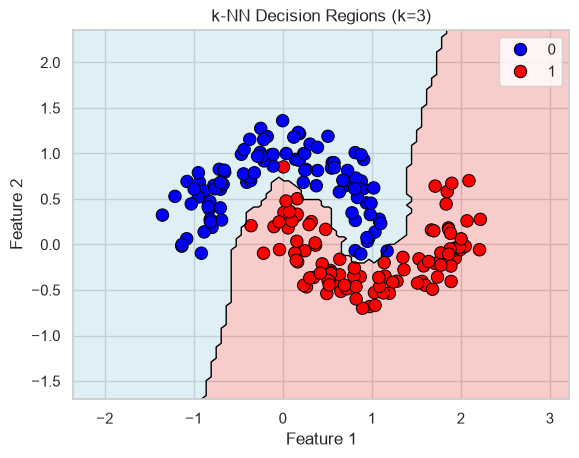

(array([0, 1]), array([5105, 4895]))
(array([0, 1]), array([100, 100]))


In [7]:
visualize_knn_model(X, y, 3, 2)

In [8]:
def compute_knn_train_test_error(X_train, y_train, k, distance_func):
    training_error = 0
    test_error = 0

    for i in range(len(X_train)):
        # Training error (point included)
        y_pred = knn_predict(X_train, y_train, X_train[i], None, k, distance_func)
        training_error += abs(y_pred - y_train[i])

        # Test error (leave this point out)
        X_without_i = np.delete(X_train, i, axis=0)
        y_without_i = np.delete(y_train, i)

        y_pred = knn_predict(X_without_i, y_without_i, X_train[i], None, k, distance_func)
        test_error += abs(y_pred - y_train[i])

    training_error
    test_error

    print("Training error:", training_error)
    print("LOOCV test error:", test_error)

    return training_error, test_error


### Part 2: Neural Network

In [9]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y = training_record

    y_pred = int(w1 * x1 + w2 * x2 + b >= 0)
    error = y - y_pred

    w1 += learning_rate * error * x1
    w2 += learning_rate * error * x2
    b += learning_rate * error

    return w1, w2, b

In [10]:
def train_neuron(training_record, learning_rate, w, b,
                 cost_derivative, activation_derivative):
    x, y = training_record
    z = w * x + b

    # Activation and its derivative
    if activation_derivative == "sigmoid":
        y_pred = 1 / (1 + np.exp(-z))
        da = y_pred * (1 - y_pred)
    elif activation_derivative == "tanh":
        y_pred = np.tanh(z)
        da = 1 - y_pred**2
    elif activation_derivative == "relu":
        y_pred = max(0, z)
        da = 1 if z > 0 else 0
    else:
        raise ValueError("Unknown activation")

    # Cost derivative
    if cost_derivative == "squared_error":
        dc = 2 * (y_pred - y)
    elif cost_derivative == "cross_entropy":
        if activation_derivative != "sigmoid":
            raise ValueError("Binary cross-entropy requires sigmoid")
        eps = 1e-12
        p = np.clip(y_pred, eps, 1 - eps)
        dc = (p - y) / (p * (1 - p))
    else:
        raise ValueError("Unknown cost function")

    # Gradient descent
    delta = dc * da
    w -= learning_rate * delta * x
    b -= learning_rate * delta

    return w, b

### Report: Question 3

In [14]:
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

X_tests = [[0.40, 0.45], [0.08, 0.78], [0.75, -0.15]]
distance_functs = [1, 2]
ks = [1, 3, 5]

for X_test in X_tests:
    print(f"X_test: {X_test}")
    for distance_func in distance_functs:
        print(f"Distance function: {distance_func}")
        for k in ks:
            print(f"k: {k}")
            knn_predict(X, y, X_test, None, k, distance_func, verbose = True)

X_test: [0.4, 0.45]
Distance function: 1
k: 1
Vote:  0
k: 3
Vote:  1
Vote:  0
Vote:  1
k: 5
Vote:  1
Vote:  1
Vote:  1
Vote:  0
Vote:  1
Distance function: 2
k: 1
Vote:  0
k: 3
Vote:  1
Vote:  0
Vote:  1
k: 5
Vote:  1
Vote:  1
Vote:  1
Vote:  0
Vote:  1
X_test: [0.08, 0.78]
Distance function: 1
k: 1
Vote:  1
k: 3
Vote:  0
Vote:  0
Vote:  1
k: 5
Vote:  0
Vote:  0
Vote:  0
Vote:  1
Vote:  0
Distance function: 2
k: 1
Vote:  1
k: 3
Vote:  0
Vote:  1
Vote:  0
k: 5
Vote:  0
Vote:  0
Vote:  0
Vote:  1
Vote:  0
X_test: [0.75, -0.15]
Distance function: 1
k: 1
Vote:  1
k: 3
Vote:  1
Vote:  1
Vote:  0
k: 5
Vote:  1
Vote:  1
Vote:  0
Vote:  0
Vote:  1
Distance function: 2
k: 1
Vote:  0
k: 3
Vote:  1
Vote:  1
Vote:  0
k: 5
Vote:  1
Vote:  1
Vote:  0
Vote:  0
Vote:  1


### Report: Question 4

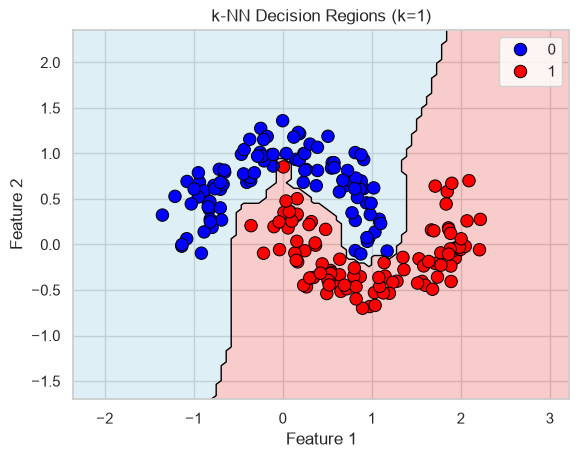

(array([0, 1]), array([5106, 4894]))
(array([0, 1]), array([100, 100]))


In [15]:
visualize_knn_model(X, y, 1, 2)

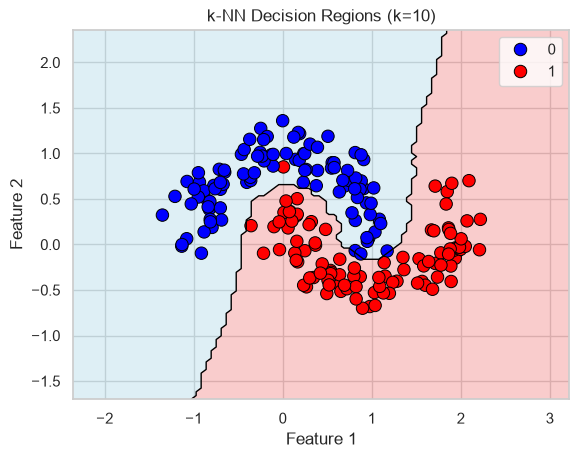

(array([0, 1]), array([5107, 4893]))
(array([0, 1]), array([100, 100]))


In [16]:
visualize_knn_model(X, y, 10, 2)